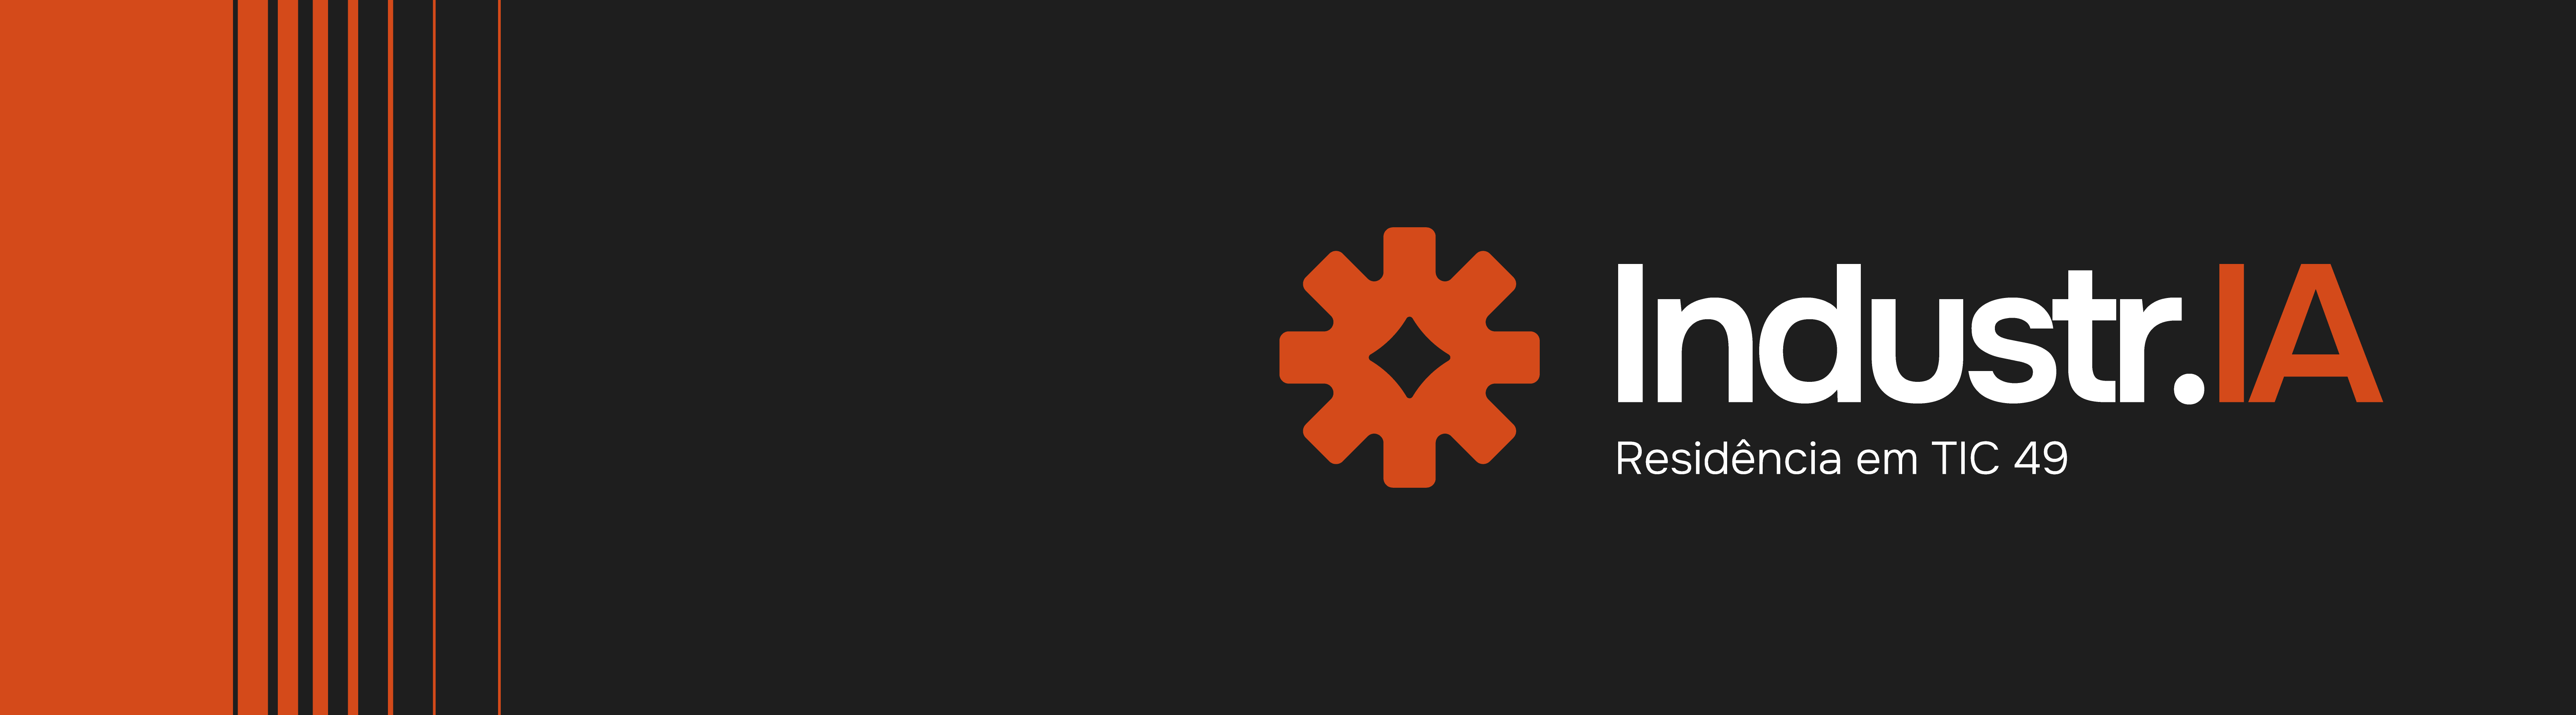
# 🤖 Laboratórios de decisão técnica

## Encontro 3, testar, validar e defender

### KIT-023, notebook do teste
**Executar o teste desenhado pelo squad, em um dos três caminhos disponíveis, e converter o resultado em revisão da decisão registrada nos instrumentos do encontro.**

---

## 📋 Sobre este notebook

Este notebook é **demonstrativo**, com **dois pontos de completar por caminho**, e foi projetado para a fase de execução do teste, de 50 minutos.

No **Google Colab**:

1. Selecione um ambiente de execução **CPU** (GPU não é necessária).
2. Confirme que os quatro arquivos CSV da turma estão na sessão, ao lado do notebook.
3. Execute as seções 1 a 4, escolha **um** dos três caminhos e execute apenas as seções dele.

✅ Não é necessária nenhuma chave de API.  
✅ Não é necessário contratar serviços pagos.  
✅ Usa apenas pandas, numpy, scikit-learn e matplotlib, pré-instalados no Colab.

Os dados vêm no ambiente da turma, e não por download: são os quatro conjuntos do caso, com cerca de 2,3 MB somados. O caminho mais pesado monta a tabela de janelas e treina um classificador leve em segundos, na CPU.

> ℹ️ Os resultados são determinísticos para uma mesma versão das bibliotecas, porque a semente aleatória é fixada. Entre versões diferentes do scikit-learn, os números podem variar na segunda casa decimal; as conclusões do teste não mudam.

---

## 🎯 Objetivo

A pergunta central deste notebook é:

> **A evidência que o squad consegue produzir hoje sustenta a decisão que ele já tomou?**

E, mais importante:

> **Qual é o limite dessa evidência, e o que ela não autoriza a afirmar na defesa?**

Executar tudo não é o objetivo. Cada caminho responde a uma pergunta diferente, e escolher um deles é parte do teste.

---

## 🔍 O que observar durante a execução

Enquanto acompanha os exemplos, procure identificar:

- Se o **critério de sucesso** foi escrito antes do resultado ou depois dele;
- Qual é a **unidade de observação** de cada número, isto é o equipamento, a janela ou a ordem de serviço;
- O que o **intervalo**, a **prevalência** e o **tamanho da amostra** dizem sobre a confiança de cada resultado;
- Quais campos já existiam no momento em que a predição seria feita, e quais **só passam a existir depois do evento**;
- Que linha da matriz de validação e da proposta técnica cada resultado altera.

> 🚀 Cada caminho termina com uma célula de resposta e duas perguntas para reflexão, que ligam o resultado aos instrumentos KIT-011 e KIT-012. Não há respostas no notebook.

## 🎯 Objetivos de aprendizagem

Ao acompanhar este notebook, procure observar quatro aspectos:

1. O **critério de sucesso** é declarado antes da execução, e não escolhido depois de ver o número.
2. Cada caminho produz um **tipo diferente de evidência**, e a escolha do caminho é parte do teste.
3. Um resultado vem sempre com o seu **limite**, seja o intervalo de reamostragem, a prevalência da
   classe rara ou o tamanho da amostra inspecionada.
4. A evidência só vale quando o squad a converte em **revisão da decisão** registrada nos
   instrumentos do encontro.

---

## 📚 Vocabulário utilizado

Os seguintes termos aparecem ao longo do notebook e estão definidos no glossário do curso base:

- janela de observação e horizonte de predição
- exposição em equipamento-ano
- reamostragem com reposição
- classe rara, sensibilidade e precisão
- vazamento de atributo
- concordância entre rótulo e evidência

> Se algum termo parecer novo, consulte o glossário do módulo indicado antes de prosseguir.

## 1. Preparação

O notebook usa pandas, numpy, scikit-learn e matplotlib, todas pré-instaladas no Colab. A semente
é fixada em uma constante única para que a reamostragem e a divisão de dados repitam os mesmos
resultados em qualquer execução, inclusive quando o mentor refizer o seu teste.

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd

SEED = 42
gerador = np.random.default_rng(SEED)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)

## 2. Carga dos dados, com verificação de disponibilidade

Os quatro conjuntos descrevem a frota de compressores, a telemetria diária, as ordens de serviço e
os pedidos de garantia do período coberto pelo caso. Eles vêm no ambiente da turma, ao lado deste
notebook.

A célula abaixo verifica se os quatro arquivos estão no lugar antes de qualquer outra coisa: se
faltar algum, é melhor descobrir agora, com uma mensagem clara.

O caminho dos dados é uma constante única. Se você tiver carregado os arquivos em outra pasta da
sessão, altere apenas essa constante e execute a célula novamente. Todas as seções seguintes
dependem desta.

In [ ]:
CAMINHO_DADOS = Path(".")

ARQUIVOS = {
    "frota": "d1_frota.csv",
    "telemetria": "d2_telemetria.csv",
    "ordens": "d3_ordens.csv",
    "garantia": "d4_garantia.csv",
}

ausentes = [nome for nome in ARQUIVOS.values() if not (CAMINHO_DADOS / nome).exists()]

if ausentes:
    print(f"ATENÇÃO: não encontrei em {CAMINHO_DADOS.resolve()} os arquivos: {ausentes}")
    print("Os quatro CSV vêm no ambiente da turma. Carregue-os na sessão do Colab com")
    print("files.upload() do pacote google.colab, ou monte o Drive na pasta da turma, mantendo")
    print("os mesmos nomes de arquivo, e execute esta célula novamente.")
else:
    dados = {chave: pd.read_csv(CAMINHO_DADOS / nome) for chave, nome in ARQUIVOS.items()}
    dados["frota"]["data_inicio_garantia"] = pd.to_datetime(dados["frota"]["data_inicio_garantia"])
    dados["telemetria"]["data"] = pd.to_datetime(dados["telemetria"]["data"])
    dados["ordens"]["data_abertura"] = pd.to_datetime(dados["ordens"]["data_abertura"])
    dados["garantia"]["data"] = pd.to_datetime(dados["garantia"]["data"])
    dados["ordens"]["pecas_trocadas"] = dados["ordens"]["pecas_trocadas"].fillna("")
    for chave, tabela in dados.items():
        print(f"{chave}: {tabela.shape[0]} linhas, {tabela.shape[1]} colunas")
    print()
    print("Período coberto pelas ordens:",
          dados["ordens"]["data_abertura"].min().date(), "a",
          dados["ordens"]["data_abertura"].max().date())

## 3. Recorte comum aos três caminhos

Antes de escolher o caminho, o notebook monta dois objetos que os três usam: a lista de peças sob
suspeita, que vem do Mapa Técnico do squad, e um resumo por equipamento com **exposição**,
**contagem de eventos** e **regime de uso** observado na telemetria.

A lista de peças vem preenchida com os códigos que o caso destaca. Se o seu Mapa apontou outras
peças, altere a constante: todo o resto do notebook passa a valer para a sua lista.

O regime de uso é lido por média móvel do ciclo de trabalho, e não pelo valor de um dia isolado,
porque um dia alto não caracteriza operação sustentada. As faixas de ciclo são terços da
distribuição da frota, o que evita fixar um limite arbitrário antes de olhar os dados.

In [ ]:
PECAS_SOB_SUSPEITA = ["VS-212", "VA-118"]

JANELA_MEDIA_MOVEL_DIAS = 14
MINIMO_DIAS_VALIDOS_JANELA = 10
MINIMO_DIAS_VALIDOS_EQUIPAMENTO = 150
FAIXAS_CICLO = ["baixa", "media", "alta"]


def marcar_pecas_suspeitas(ordens, pecas=None):
    # Retorna serie booleana: a ordem trocou ao menos uma das pecas sob suspeita.
    pecas = PECAS_SOB_SUSPEITA if pecas is None else pecas
    lista = ordens["pecas_trocadas"].fillna("")
    marca = pd.Series(False, index=ordens.index)
    for codigo in pecas:
        marca = marca | lista.str.contains(codigo, regex=False)
    return marca


def resumo_por_equipamento(dados, pecas=None):
    # Uma linha por equipamento: exposicao em anos, eventos das pecas sob suspeita,
    # regime de uso observado na telemetria e faixa de ciclo em tercos da frota.
    frota = dados["frota"].copy()
    telemetria = dados["telemetria"]
    ordens = dados["ordens"]

    inicio = ordens["data_abertura"].min()
    fim = ordens["data_abertura"].max()
    comeco = frota["data_inicio_garantia"].clip(lower=inicio).clip(upper=fim)
    frota["exposicao_anos"] = ((fim - comeco).dt.days + 1) / 365.0

    eventos = ordens.loc[marcar_pecas_suspeitas(ordens, pecas)].groupby("id_equipamento").size()
    frota["eventos"] = frota["id_equipamento"].map(eventos).fillna(0).astype(int)

    ordenada = telemetria.sort_values(["id_equipamento", "data"])
    media_movel = (ordenada.groupby("id_equipamento")["ciclo_trabalho_medio"]
                   .rolling(JANELA_MEDIA_MOVEL_DIAS, min_periods=MINIMO_DIAS_VALIDOS_JANELA)
                   .mean())
    ciclo_sustentado = media_movel.groupby(level=0).mean()
    dias_validos = ordenada.groupby("id_equipamento")["ciclo_trabalho_medio"].count()

    frota["ciclo_sustentado"] = frota["id_equipamento"].map(ciclo_sustentado)
    frota["dias_validos"] = frota["id_equipamento"].map(dias_validos).fillna(0).astype(int)
    frota["com_telemetria_suficiente"] = frota["dias_validos"] >= MINIMO_DIAS_VALIDOS_EQUIPAMENTO
    observavel = frota.loc[frota["com_telemetria_suficiente"], "ciclo_sustentado"]
    cortes = observavel.quantile([0, 1 / 3, 2 / 3, 1]).to_numpy()
    frota["faixa_ciclo"] = pd.cut(frota["ciclo_sustentado"], bins=cortes,
                                  labels=FAIXAS_CICLO, include_lowest=True)
    return frota


equipamentos = resumo_por_equipamento(dados)
print(equipamentos[["id_equipamento", "id_planta", "classe_ambiente", "faixa_ciclo",
                    "dias_validos", "exposicao_anos", "eventos"]].head(8).to_string(index=False))
print()
print("Equipamentos com telemetria suficiente para leitura de regime:",
      int(equipamentos["com_telemetria_suficiente"].sum()), "de", len(equipamentos))
print("Ordens que trocaram peça sob suspeita:", int(marcar_pecas_suspeitas(dados["ordens"]).sum()))

## 4. Escolha do caminho e critério declarado antes

Os três caminhos abaixo produzem evidências diferentes sobre a mesma dor. Escolha **um** e registre,
na célula de resposta desta seção, qual escolheu, por quê, e qual é o critério numérico de sucesso
que você declara **antes** de executar.

- **Caminho A, analítico**: taxa de falha por faixa de ciclo de trabalho e por classe de ambiente,
  com intervalo por reamostragem. Responde se a concentração que o squad supõe existe nos dados.
- **Caminho B, preditivo**: classificador de referência sobre janela de observação, com métrica
  adequada à classe rara. Responde se há sinal suficiente para antecipar a falha.
- **Caminho C, sobre dados**: concordância entre causa registrada e peça trocada, com estimativa do
  ganho de corrigir o rótulo. Responde se o limite está no modelo ou no dado.

Cada caminho pede que você escreva o critério numérico no primeiro `# TODO` da sua célula de
exercício. Escrever o critério depois de ver o resultado invalida o teste, e é isso que a ordem das
células impede.

### ✍️ Sua resposta

Edite esta célula e registre, em duas a quatro frases, no espírito do instrumento KIT-011:

- **Caminho escolhido**: qual dos três, em uma palavra.
- **Por que este**: que pergunta da sua hipótese ele responde, e qual das outras duas você abre mão
  de responder hoje.
- **Critério declarado**: o número que separa sustentar de não sustentar, e de onde ele vem.

*Escreva aqui a sua resposta.*

## 5. Caminho A, analítico

O caminho A compara a **taxa de falha por exposição** entre grupos de equipamentos. A taxa é o
número de eventos dividido pela exposição em equipamento-ano, e não pela contagem de equipamentos:
um equipamento instalado no meio do período não esteve exposto o mesmo tempo que os demais.

A célula seguinte é demonstrativa. Ela cruza faixa de ciclo com classe de ambiente e imprime a
taxa de cada célula do cruzamento, com o número de eventos que a sustenta. Uma célula com poucos
eventos produz taxa instável, e é por isso que a contagem aparece ao lado.

In [ ]:
def taxa_por_grupo(equipamentos, colunas):
    # Taxa de eventos por equipamento-ano em cada grupo, com eventos e exposicao ao lado.
    elegiveis = equipamentos.loc[equipamentos["com_telemetria_suficiente"]]
    agregado = elegiveis.groupby(colunas, observed=True).agg(
        equipamentos=("id_equipamento", "count"),
        eventos=("eventos", "sum"),
        exposicao_anos=("exposicao_anos", "sum"),
    )
    agregado["taxa_por_ano"] = agregado["eventos"] / agregado["exposicao_anos"]
    return agregado.reset_index()


cruzamento = taxa_por_grupo(equipamentos, ["faixa_ciclo", "classe_ambiente"])
print(cruzamento.to_string(index=False))
print()
print("Por faixa de ciclo, ignorando o ambiente:")
print(taxa_por_grupo(equipamentos, ["faixa_ciclo"]).to_string(index=False))
print()
print("Por classe de ambiente, ignorando o ciclo:")
print(taxa_por_grupo(equipamentos, ["classe_ambiente"]).to_string(index=False))

A tabela acima dá pontos, não intervalos. Com poucas dezenas de eventos, uma diferença entre duas
células pode ser apenas variação amostral. A célula abaixo estima o intervalo da **razão** entre um
grupo e o restante por reamostragem com reposição dos equipamentos, o que preserva a unidade de
observação correta: o equipamento, e não o dia de telemetria.

In [ ]:
REAMOSTRAGENS = 2000
PERCENTIS_INTERVALO = (2.5, 97.5)


def razao_entre_grupos(equipamentos, mascara_grupo):
    # Razao entre a taxa do grupo marcado e a taxa dos demais equipamentos elegiveis.
    elegiveis = equipamentos.loc[equipamentos["com_telemetria_suficiente"]]
    grupo = elegiveis.loc[mascara_grupo.loc[elegiveis.index]]
    restante = elegiveis.loc[~mascara_grupo.loc[elegiveis.index]]
    taxa_grupo = grupo["eventos"].sum() / grupo["exposicao_anos"].sum()
    taxa_restante = restante["eventos"].sum() / restante["exposicao_anos"].sum()
    return taxa_grupo / taxa_restante


def intervalo_da_razao(equipamentos, mascara_grupo, reamostragens=REAMOSTRAGENS):
    # Intervalo percentilico da razao, por reamostragem com reposicao dos equipamentos.
    elegiveis = equipamentos.loc[equipamentos["com_telemetria_suficiente"]].reset_index(drop=True)
    marca = mascara_grupo.loc[
        equipamentos["com_telemetria_suficiente"][equipamentos["com_telemetria_suficiente"]].index
    ].reset_index(drop=True)
    razoes = []
    for _ in range(reamostragens):
        sorteio = gerador.integers(0, len(elegiveis), len(elegiveis))
        amostra = elegiveis.iloc[sorteio]
        marca_amostra = marca.iloc[sorteio]
        grupo = amostra.loc[marca_amostra.to_numpy()]
        restante = amostra.loc[~marca_amostra.to_numpy()]
        if grupo["exposicao_anos"].sum() == 0 or restante["eventos"].sum() == 0:
            continue
        taxa_grupo = grupo["eventos"].sum() / grupo["exposicao_anos"].sum()
        taxa_restante = restante["eventos"].sum() / restante["exposicao_anos"].sum()
        razoes.append(taxa_grupo / taxa_restante)
    razoes = np.asarray(razoes)
    return tuple(np.percentile(razoes, PERCENTIS_INTERVALO)), razoes


exemplo = equipamentos["faixa_ciclo"].eq("alta")
razao_exemplo = razao_entre_grupos(equipamentos, exemplo)
intervalo_exemplo, amostras_exemplo = intervalo_da_razao(equipamentos, exemplo)
print(f"Exemplo, faixa de ciclo alta contra as demais: razão {razao_exemplo:.3f}")
print(f"Intervalo de {PERCENTIS_INTERVALO[0]} a {PERCENTIS_INTERVALO[1]} por cento: "
      f"{intervalo_exemplo[0]:.3f} a {intervalo_exemplo[1]:.3f}")
print(f"Reamostragens aproveitadas: {len(amostras_exemplo)} de {REAMOSTRAGENS}")

## 6. Exercício prático do caminho A: o grupo da sua hipótese

Agora é a sua vez. O exemplo acima usou um grupo qualquer, definido por uma única coluna. A sua
hipótese provavelmente define o grupo por mais de uma condição. Complete os pontos marcados com
`# TODO` na célula abaixo e rode a autoverificação em seguida.

- **Passo A**: declare o critério numérico, isto é a razão mínima entre o grupo e o restante a
  partir da qual você considera que a evidência sustenta a hipótese. Declare antes de calcular.
- **Passo B**: defina a máscara do grupo da sua hipótese sobre a tabela `equipamentos` usando as
  colunas que apareceram na seção 5, calcule a razão e o intervalo com `razao_entre_grupos` e
  `intervalo_da_razao`, e registre a decisão comparando o limite inferior do intervalo com o
  critério declarado, e não a razão pontual com o critério.

In [ ]:
DECISOES_POSSIVEIS = ["sustenta", "nao sustenta"]

# Passo A: o criterio numerico, declarado antes de calcular
# TODO: atribua um numero maior que 1 a razao minima que sustenta a sua hipotese
razao_minima_declarada = ...

# Passo B: o grupo da sua hipotese, a razao com intervalo, e a decisao pelo limite inferior
# TODO: monte a mascara booleana do grupo por mais de uma condicao sobre a tabela equipamentos,
# calcule razao e intervalo com as funcoes da secao 5, e atribua a decisao comparando o limite
# inferior do intervalo com razao_minima_declarada, usando um dos valores de DECISOES_POSSIVEIS
mascara_hipotese = ...
razao_observada = ...
intervalo_observado = ...
decisao_caminho_a = ...

In [ ]:
# Autoverificação: rode após completar os TODOs. Nenhum valor esperado é revelado.
assert isinstance(razao_minima_declarada, (int, float)) and razao_minima_declarada > 1, \
    "Revise o passo A: o critério precisa ser um número maior que 1."
assert isinstance(mascara_hipotese, pd.Series) and mascara_hipotese.dtype == bool, \
    "Revise o passo B: a máscara precisa ser uma série booleana sobre a tabela equipamentos."
assert mascara_hipotese.index.equals(equipamentos.index), \
    "Revise o passo B: a máscara precisa ter o mesmo índice da tabela equipamentos."
assert 0 < int(mascara_hipotese.sum()) < len(equipamentos), \
    "Revise o passo B: o grupo não pode ser vazio nem conter a frota inteira."
assert isinstance(razao_observada, float) and np.isfinite(razao_observada), \
    "Revise o passo B: a razão precisa ser um número finito."
assert isinstance(intervalo_observado, tuple) and len(intervalo_observado) == 2 \
    and intervalo_observado[0] < intervalo_observado[1], \
    "Revise o passo B: o intervalo precisa ser um par ordenado."
assert int(mascara_hipotese.sum()) >= 5, \
    "Revise o passo B: um grupo com menos de cinco equipamentos não sustenta intervalo."
assert decisao_caminho_a in DECISOES_POSSIVEIS, \
    "Revise o passo B: a decisão precisa ser um dos valores de DECISOES_POSSIVEIS."
esperado = "sustenta" if intervalo_observado[0] >= razao_minima_declarada else "nao sustenta"
assert decisao_caminho_a == esperado, \
    "Revise o passo B: a decisão não segue do limite inferior do intervalo contra o seu critério."

print("✅ Exercício concluído. Agora registre a sua resposta na célula abaixo.")

### ✍️ Sua resposta

Edite esta célula e registre, em duas a quatro frases, no espírito dos instrumentos KIT-011 e
KIT-012:

- **O que o teste mostrou**: a razão e o intervalo, com o número de eventos que os sustenta.
- **O que isso muda**: qual linha da sua hipótese ou da sua decisão passa a ter evidência, e qual
  continua sem.
- **Limite do resultado**: o que este recorte não é capaz de distinguir.

*Escreva aqui a sua resposta.*

### Perguntas para reflexão do caminho A

Não há respostas no notebook.

1. O intervalo do seu grupo ficou largo ou estreito? Olhe a coluna de eventos do cruzamento da
   seção 5 e diga o que precisaria mudar na coleta para estreitá-lo, sem mudar o modelo.

2. Se a razão do seu grupo composto for parecida com a razão de uma das condições isoladas, o que
   isso diz sobre a hipótese que o squad levou para o Encontro 2?

## 7. Caminho B, preditivo

O caminho B transforma o histórico em uma tabela de **janelas**: cada linha resume uma janela de
observação de um equipamento e recebe um rótulo que diz se houve evento das peças sob suspeita no
horizonte seguinte. A janela desliza no tempo com passo fixo.

Duas consequências disso governam o resto do caminho. A primeira é que a classe positiva é rara, e
a acurácia global deixa de dizer algo útil. A segunda é que só pode entrar como atributo aquilo que
já existia no fim da janela de observação: campos que descrevem o atendimento, a peça trocada e a
decisão de garantia passam a existir depois do evento, e usá-los como atributo produz um resultado
excelente e falso.

In [ ]:
JANELA_OBSERVACAO_DIAS = 30
HORIZONTE_DIAS = 30
PASSO_JANELA_DIAS = 7

ATRIBUTOS_DA_JANELA = [
    "ciclo_medio", "temp_maxima_media", "temp_maxima_pico", "pressao_media",
    "horas_somadas", "partidas_medias", "fracao_incompleta", "dias_observados",
]
CAMPOS_POSTERIORES_AO_EVENTO = [
    "duracao_horas_no_horizonte", "pecas_no_horizonte", "valor_pleiteado_no_horizonte",
]


def construir_janelas(dados, pecas=None):
    # Uma linha por equipamento e janela. Alem dos atributos da janela de observacao, a tabela
    # carrega de proposito tres campos colhidos no horizonte, para o teste de sanidade.
    telemetria = dados["telemetria"]
    ordens = dados["ordens"]
    garantia = dados["garantia"]

    suspeitas = ordens.loc[marcar_pecas_suspeitas(ordens, pecas)]
    por_equipamento_suspeitas = {k: v.sort_values("data_abertura")
                                 for k, v in suspeitas.groupby("id_equipamento")}
    com_valor = ordens.merge(garantia[["id_ordem", "valor_pleiteado"]], on="id_ordem", how="left")
    por_equipamento_ordens = {k: v.sort_values("data_abertura")
                              for k, v in com_valor.groupby("id_equipamento")}

    inicio = ordens["data_abertura"].min()
    fim = ordens["data_abertura"].max()
    total_dias = (fim - inicio).days + 1
    deslocamentos = range(0, total_dias - (JANELA_OBSERVACAO_DIAS + HORIZONTE_DIAS) + 1,
                          PASSO_JANELA_DIAS)

    linhas = []
    for equipamento, bloco in telemetria.groupby("id_equipamento", sort=True):
        bloco = bloco.set_index("data").sort_index()
        eventos = por_equipamento_suspeitas.get(equipamento)
        todas = por_equipamento_ordens.get(equipamento)
        for deslocamento in deslocamentos:
            t0 = inicio + pd.Timedelta(days=int(deslocamento))
            t1 = t0 + pd.Timedelta(days=JANELA_OBSERVACAO_DIAS)
            t2 = t1 + pd.Timedelta(days=HORIZONTE_DIAS)
            observacao = bloco.loc[(bloco.index >= t0) & (bloco.index < t1)]
            if len(observacao) == 0:
                continue
            rotulo = 0
            if eventos is not None:
                no_horizonte = eventos.loc[(eventos["data_abertura"] >= t1)
                                           & (eventos["data_abertura"] < t2)]
                rotulo = int(len(no_horizonte) > 0)
            duracao = np.nan
            pecas_horizonte = ""
            valor = np.nan
            if todas is not None:
                ordens_horizonte = todas.loc[(todas["data_abertura"] >= t1)
                                             & (todas["data_abertura"] < t2)]
                if len(ordens_horizonte):
                    duracao = float(ordens_horizonte["duracao_horas"].max())
                    pecas_horizonte = ";".join(ordens_horizonte["pecas_trocadas"].astype(str))
                    valor = float(ordens_horizonte["valor_pleiteado"].max())
            linhas.append({
                "id_equipamento": equipamento,
                "inicio_janela": t0,
                "dias_observados": int(observacao["ciclo_trabalho_medio"].notna().sum()),
                "ciclo_medio": observacao["ciclo_trabalho_medio"].mean(),
                "temp_maxima_media": observacao["temp_descarga_maxima"].mean(),
                "temp_maxima_pico": observacao["temp_descarga_maxima"].max(),
                "pressao_media": observacao["pressao_descarga_media"].mean(),
                "horas_somadas": observacao["horas_operacao"].sum(),
                "partidas_medias": observacao["contagem_partidas"].mean(),
                "fracao_incompleta": observacao["transmissao_incompleta"].mean(),
                "duracao_horas_no_horizonte": duracao,
                "pecas_no_horizonte": pecas_horizonte,
                "valor_pleiteado_no_horizonte": valor,
                "rotulo": rotulo,
            })
    return pd.DataFrame(linhas)


janelas = construir_janelas(dados)
prevalencia = janelas["rotulo"].mean()
print(f"Janelas construídas: {len(janelas)}")
print(f"Janelas com evento no horizonte: {int(janelas['rotulo'].sum())}")
print(f"Prevalência da classe positiva: {prevalencia:.4f}")
print(f"Acurácia de um classificador que responde sempre a classe majoritária: {1 - prevalencia:.4f}")

A divisão entre treino e teste é **temporal**, e não aleatória: o modelo é treinado no início do
período e avaliado no final, que é a situação real de uso. Uma divisão aleatória colocaria janelas
do mesmo equipamento e da mesma semana nos dois lados e produziria um resultado otimista.

A célula abaixo treina um classificador de referência, imprime as métricas que importam para classe
rara e desenha a curva de precisão contra sensibilidade.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve
import matplotlib.pyplot as plt

FRACAO_TREINO_NO_TEMPO = 0.7


def dividir_no_tempo(janelas, fracao=FRACAO_TREINO_NO_TEMPO):
    # Divisao temporal: as primeiras janelas treinam, as ultimas avaliam.
    ordenadas = janelas.sort_values("inicio_janela").reset_index(drop=True)
    corte = ordenadas["inicio_janela"].quantile(fracao)
    treino = ordenadas.loc[ordenadas["inicio_janela"] <= corte]
    teste = ordenadas.loc[ordenadas["inicio_janela"] > corte]
    return treino, teste, corte


def treinar_referencia(treino, teste, atributos):
    # Classificador de referencia, com os atributos que a pessoa escolheu.
    modelo = RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5, class_weight="balanced", random_state=SEED)
    x_treino = treino[atributos].fillna(0.0)
    x_teste = teste[atributos].fillna(0.0)
    modelo.fit(x_treino, treino["rotulo"])
    escore = modelo.predict_proba(x_teste)[:, 1]
    return modelo, escore


def sensibilidade_na_precisao(rotulo, escore, precisao_fixada):
    # Maior sensibilidade alcancavel sem cair abaixo da precisao fixada.
    precisao, sensibilidade, _ = precision_recall_curve(rotulo, escore)
    admissiveis = sensibilidade[precisao >= precisao_fixada]
    return float(admissiveis.max()) if len(admissiveis) else 0.0


treino, teste, corte = dividir_no_tempo(janelas)
print(f"Corte temporal em {corte.date()}: {len(treino)} janelas de treino, {len(teste)} de teste")
print(f"Positivos no treino: {int(treino['rotulo'].sum())}, no teste: {int(teste['rotulo'].sum())}")

modelo_exemplo, escore_exemplo = treinar_referencia(treino, teste, ATRIBUTOS_DA_JANELA)
print(f"Precisão média no teste: {average_precision_score(teste['rotulo'], escore_exemplo):.3f}")

precisao, sensibilidade, _ = precision_recall_curve(teste["rotulo"], escore_exemplo)
plt.figure(figsize=(6, 4))
plt.plot(sensibilidade, precisao)
plt.axhline(teste["rotulo"].mean(), linestyle="--", linewidth=1)
plt.xlabel("Sensibilidade")
plt.ylabel("Precisão")
plt.title("Precisão contra sensibilidade no período de teste")
plt.tight_layout()
plt.show()
print("A linha tracejada é a precisão de um classificador que sorteia, isto é a prevalência.")

Antes do exercício, o teste de sanidade. A função abaixo recusa qualquer conjunto de atributos que
contenha um campo colhido no horizonte. Ela existe porque o resultado desse erro não parece um erro:
a métrica sobe, a curva fica quase perfeita, e nada no número denuncia o problema.

In [ ]:
def teste_sanidade_atributos(atributos):
    # Recusa atributo que so passa a existir depois do evento que se quer prever.
    posteriores = [coluna for coluna in atributos if coluna in CAMPOS_POSTERIORES_AO_EVENTO]
    if posteriores:
        raise ValueError(
            "Teste de sanidade recusou o conjunto de atributos. Estes campos só passam a existir "
            f"depois do evento que se quer prever, e não estariam disponíveis no fim da janela de "
            f"observação: {posteriores}.")
    desconhecidos = [coluna for coluna in atributos if coluna not in ATRIBUTOS_DA_JANELA]
    if desconhecidos:
        raise ValueError(
            f"Estes nomes não são atributos da janela de observação: {desconhecidos}.")
    return {"atributos_aceitos": list(atributos), "campos_posteriores_encontrados": []}


print(teste_sanidade_atributos(["ciclo_medio", "temp_maxima_media"]))

## 8. Exercício prático do caminho B: o seu conjunto de atributos

Agora é a sua vez. Complete os pontos marcados com `# TODO` na célula abaixo e rode a
autoverificação em seguida.

- **Passo A**: declare o critério, isto é a precisão que você fixa e a sensibilidade mínima que
  torna o resultado útil para a coordenação de garantia. Declare antes de treinar.
- **Passo B**: escolha o conjunto de atributos, passe-o pelo `teste_sanidade_atributos`, treine com
  `treinar_referencia`, calcule a sensibilidade com `sensibilidade_na_precisao` e registre a decisão
  comparando essa sensibilidade com a mínima que você declarou.

In [ ]:
DECISOES_POSSIVEIS_B = ["sustenta", "nao sustenta"]

# Passo A: o criterio, declarado antes de treinar
# TODO: fixe a precisao entre 0 e 1 e a sensibilidade minima entre 0 e 1
precisao_fixada = ...
sensibilidade_minima_declarada = ...

# Passo B: os atributos, o teste de sanidade, o treino, a sensibilidade e a decisao
# TODO: escolha os atributos entre os de ATRIBUTOS_DA_JANELA, rode o teste de sanidade, treine com
# treinar_referencia, calcule a sensibilidade com sensibilidade_na_precisao e atribua a decisao
# comparando-a com sensibilidade_minima_declarada, usando um dos valores de DECISOES_POSSIVEIS_B
atributos_escolhidos = ...
relatorio_sanidade = ...
modelo, escore_teste = ...
sensibilidade_obtida = ...
decisao_caminho_b = ...

In [ ]:
# Autoverificação: rode após completar os TODOs. Nenhum valor esperado é revelado.
assert isinstance(precisao_fixada, float) and 0 < precisao_fixada < 1, \
    "Revise o passo A: a precisão fixada precisa estar entre 0 e 1."
assert isinstance(sensibilidade_minima_declarada, float) \
    and 0 < sensibilidade_minima_declarada <= 1, \
    "Revise o passo A: a sensibilidade mínima precisa estar entre 0 e 1."
assert isinstance(atributos_escolhidos, list) and len(atributos_escolhidos) >= 2, \
    "Revise o passo B: escolha pelo menos dois atributos, em uma lista."
assert isinstance(relatorio_sanidade, dict) \
    and relatorio_sanidade.get("atributos_aceitos") == atributos_escolhidos, \
    "Revise o passo B: passe exatamente os seus atributos pelo teste de sanidade."
assert hasattr(modelo, "classes_") and len(modelo.classes_) == 2, \
    "Revise o passo B: o modelo precisa estar treinado nas duas classes."
assert isinstance(escore_teste, np.ndarray) and len(escore_teste) == len(teste), \
    "Revise o passo B: o escore precisa ter uma posição por janela do período de teste."
assert isinstance(sensibilidade_obtida, float) and 0 <= sensibilidade_obtida <= 1, \
    "Revise o passo B: a sensibilidade precisa estar entre 0 e 1."
assert decisao_caminho_b in DECISOES_POSSIVEIS_B, \
    "Revise o passo B: a decisão precisa ser um dos valores de DECISOES_POSSIVEIS_B."
esperado_b = ("sustenta" if sensibilidade_obtida >= sensibilidade_minima_declarada
              else "nao sustenta")
assert decisao_caminho_b == esperado_b, \
    "Revise o passo B: a decisão não segue da sensibilidade obtida contra o seu critério."

print("✅ Exercício concluído. Agora registre a sua resposta na célula abaixo.")

### ✍️ Sua resposta

Edite esta célula e registre, em duas a quatro frases, no espírito dos instrumentos KIT-011 e
KIT-012:

- **O que o teste mostrou**: a sensibilidade na sua precisão fixada, e quantos positivos do período
  de teste isso representa.
- **O que isso muda**: que métrica entra na sua matriz de validação, e por que não a acurácia.
- **Limite do resultado**: o que a divisão temporal e a prevalência impedem de concluir.

*Escreva aqui a sua resposta.*

### Perguntas para reflexão do caminho B

Não há respostas no notebook.

1. Suponha que alguém apresente a este squad um modelo com precisão média muito acima da que você
   obteve. Que pergunta você faria sobre os atributos antes de aceitar o número?

2. A coordenação de garantia decide caso a caso, com consequência contratual. Que profundidade de
   explicação essa decisão exige do modelo, e qual das matrizes do curso base você usaria para
   registrar essa exigência?

## 9. Caminho C, sobre dados

O caminho C não olha o modelo: olha o **rótulo**. A causa registrada vem de uma lista fechada
preenchida pelo técnico em campo, e a peça trocada vem do apontamento de material da mesma ordem.
Os dois descrevem o mesmo atendimento, então é possível medir a **concordância** entre eles.

A célula seguinte imprime uma amostra de ordens das peças sob suspeita, com o relato do técnico ao
lado, para leitura humana. A inspeção de amostra é parte do método: nenhum agregado substitui a
leitura de algumas dezenas de linhas.

In [ ]:
TAMANHO_AMOSTRA_INSPECAO = 20
CAUSAS_GENERICAS = ["desgaste_natural", "causa_nao_identificada", "corretiva_geral"]
CAUSAS_ESPECIFICAS_ESPERADAS = {
    "VS-212": ["falha_vedacao", "contaminacao_particulado"],
    "VA-118": ["falha_valvula_admissao", "contaminacao_particulado"],
}

suspeitas = dados["ordens"].loc[marcar_pecas_suspeitas(dados["ordens"])]
amostra = suspeitas.sample(TAMANHO_AMOSTRA_INSPECAO, random_state=SEED)
print(amostra[["id_ordem", "data_abertura", "causa_registrada", "pecas_trocadas",
               "relato_tecnico"]].to_string(index=False))

A leitura da amostra sugere o que medir. A célula abaixo mede, sobre todas as ordens das peças sob
suspeita, quantas registram causa genérica, e quantas registram uma causa específica compatível com
a peça efetivamente trocada. A diferença entre esses dois números é o que uma re-anotação
recuperaria.

In [ ]:
def concordancia_causa_peca(ordens, pecas=None):
    # Concordancia entre a causa registrada e a peca trocada, ordem por ordem.
    pecas = PECAS_SOB_SUSPEITA if pecas is None else pecas
    recorte = ordens.loc[marcar_pecas_suspeitas(ordens, pecas)].copy()
    esperadas = []
    for lista in recorte["pecas_trocadas"]:
        aceitas = []
        for codigo in pecas:
            if codigo in str(lista):
                aceitas.extend(CAUSAS_ESPECIFICAS_ESPERADAS.get(codigo, []))
        esperadas.append(aceitas)
    recorte["causas_compativeis"] = esperadas
    recorte["causa_generica"] = recorte["causa_registrada"].isin(CAUSAS_GENERICAS)
    recorte["causa_compativel"] = [
        causa in aceitas for causa, aceitas in zip(recorte["causa_registrada"], esperadas)
    ]
    return recorte


concordancia = concordancia_causa_peca(dados["ordens"])
print(f"Ordens das peças sob suspeita: {len(concordancia)}")
print(f"Com causa genérica: {int(concordancia['causa_generica'].sum())}")
print(f"Com causa específica compatível com a peça: {int(concordancia['causa_compativel'].sum())}")
print()
print("Distribuição da causa registrada nessas ordens:")
print(concordancia["causa_registrada"].value_counts().to_string())
print()
print("Para comparação, nas demais ordens corretivas:")
demais = dados["ordens"].loc[(dados["ordens"]["tipo_ordem"] == "corretiva")
                             & ~marcar_pecas_suspeitas(dados["ordens"])]
print(f"Com causa genérica: {demais['causa_registrada'].isin(CAUSAS_GENERICAS).mean():.3f}")

## 10. Exercício prático do caminho C: a taxa de discordância e o ganho

Agora é a sua vez. Complete os pontos marcados com `# TODO` na célula abaixo e rode a
autoverificação em seguida.

- **Passo A**: declare o critério, isto é a taxa de discordância acima da qual a intervenção nos
  dados passa à frente da troca de modelo. Declare antes de calcular.
- **Passo B**: calcule a taxa de discordância sobre a tabela `concordancia`, estime o ganho da
  re-anotação em número de ordens que passariam a ser identificáveis pelo campo de causa, e registre
  a decisão comparando a taxa observada com o critério declarado.

In [ ]:
DECISOES_POSSIVEIS_C = ["intervir nos dados", "trocar de modelo"]

# Passo A: o criterio, declarado antes de calcular
# TODO: atribua a taxa de discordancia limite, entre 0 e 1
taxa_discordancia_limite = ...

# Passo B: a taxa observada, o ganho estimado da re-anotacao e a decisao
# TODO: calcule a taxa de discordancia sobre a tabela concordancia, o ganho em numero de ordens, e
# atribua a decisao comparando a taxa com taxa_discordancia_limite, usando um dos valores de
# DECISOES_POSSIVEIS_C
taxa_discordancia_observada = ...
ganho_em_ordens = ...
decisao_caminho_c = ...

In [ ]:
# Autoverificação: rode após completar os TODOs. Nenhum valor esperado é revelado.
assert isinstance(taxa_discordancia_limite, float) and 0 < taxa_discordancia_limite < 1, \
    "Revise o passo A: a taxa limite precisa estar entre 0 e 1."
assert isinstance(taxa_discordancia_observada, float) and 0 <= taxa_discordancia_observada <= 1, \
    "Revise o passo B: a taxa observada precisa estar entre 0 e 1."
assert isinstance(ganho_em_ordens, (int, np.integer)) and 0 <= ganho_em_ordens <= len(concordancia), \
    "Revise o passo B: o ganho precisa ser um número inteiro de ordens da tabela concordancia."
assert abs(taxa_discordancia_observada - ganho_em_ordens / len(concordancia)) < 0.02, \
    "Revise o passo B: a taxa e o ganho precisam se referir ao mesmo conjunto de ordens."
assert decisao_caminho_c in DECISOES_POSSIVEIS_C, \
    "Revise o passo B: a decisão precisa ser um dos valores de DECISOES_POSSIVEIS_C."
esperado_c = ("intervir nos dados" if taxa_discordancia_observada > taxa_discordancia_limite
              else "trocar de modelo")
assert decisao_caminho_c == esperado_c, \
    "Revise o passo B: a decisão não segue da taxa observada contra o seu critério."

print("✅ Exercício concluído. Agora registre a sua resposta na célula abaixo.")

### ✍️ Sua resposta

Edite esta célula e registre, em duas a quatro frases, no espírito dos instrumentos KIT-011 e
KIT-012:

- **O que o teste mostrou**: a taxa de discordância e o número de ordens que a re-anotação
  recuperaria.
- **O que isso muda**: o que entra antes no cronograma, e qual esforço de re-anotação isso implica
  em número de ordens a revisar.
- **Limite do resultado**: o que a comparação entre causa e peça não é capaz de dizer.

*Escreva aqui a sua resposta.*

### Perguntas para reflexão do caminho C

Não há respostas no notebook.

1. A re-anotação que você dimensionou precisa de quem para ser feita, e em quanto tempo? Diga o que
   muda na proposta técnica se essa pessoa não estiver disponível no período do projeto.

2. Se a causa registrada é o campo que alimenta o painel do cliente, o que a taxa que você mediu
   diz sobre os números que a diretoria vem lendo há doze meses?

## 11. Como ler um teste de decisão

Primeiro, o **critério antes do número**. Um teste cujo limite de aceitação é escrito depois do
resultado não é teste: é justificação. A ordem das células deste notebook existe para tornar isso
visível, e a mesma ordem vale fora dele.

Segundo, a **unidade de observação**. A taxa do caminho A divide por exposição em equipamento-ano, a
reamostragem sorteia equipamentos e não dias, e a divisão do caminho B é temporal. Cada uma dessas
escolhas muda o número, e nenhuma delas aparece na métrica final.

Terceiro, o **limite junto do resultado**. Intervalo largo, classe rara, amostra pequena: o mesmo
resultado sustenta conclusões diferentes conforme o que o acompanha, e é isso que a coluna de
limites da matriz de validação registra.

Quarto, a **pergunta que o caminho não responde**. O squad escolheu um dos três caminhos hoje. Os
outros dois continuam abertos, e dizer qual deles ficou de fora é parte da defesa.